# 1. Install Required Libraries

This cell installs all Python libraries required for the preprocessing pipeline.

- **librosa** – loading and processing audio
- **soundfile** – reading and writing WAV files
- **numpy** – numerical operations on audio data
- **pandas** – data handling if needed later
- **matplotlib** – plotting audio waveforms
- **datasets** – loading the AMI Meeting Corpus
- **torchcodec** – audio decoding support for Hugging Face datasets
- **huggingface_hub** – supporting Hugging Face dataset access

Run this cell once before starting the preprocessing workflow.

In [1]:
%pip -q install librosa soundfile numpy pandas matplotlib datasets torchcodec huggingface_hub

Note: you may need to restart the kernel to use updated packages.


# 2. Check FFmpeg Installation

This cell checks whether **FFmpeg** is installed and available in the environment.

FFmpeg is a standard tool for handling audio and video files. It can be useful when working with different audio formats and is commonly used in speech-processing projects.

If FFmpeg is installed correctly, its version information will be displayed.

In [2]:
!ffmpeg -version

ffmpeg version 9.0.1 Copyright (c) 2000-2026 the FFmpeg developers
built with Apple clang version 21.0.0 (clang-2100.1.1.101)
configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/9.0.1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags= --enable-ffplay --enable-gpl --enable-libsvtav1 --enable-libopus --enable-libx264 --enable-libmp3lame --enable-libdav1d --enable-libvmaf --enable-libvpx --enable-libx265 --enable-openssl --enable-videotoolbox --enable-audiotoolbox --enable-neon
libavutil      61.  1.101 / 61.  1.101
libavcodec     63.  1.101 / 63.  1.101
libavformat    63.  1.101 / 63.  1.101
libavdevice    63.  1.101 / 63.  1.101
libavfilter    12.  1.101 / 12.  1.101
libswscale     10.  1.101 / 10.  1.101
libswresample   7.  1.101 /  7.  1.101

Exiting with exit code 0


# 3. Import Required Libraries

This cell imports the Python libraries used throughout the notebook.

The main libraries are:

- `os` – working with folders and file paths
- `subprocess` – running system commands when required
- `numpy` – numerical calculations
- `pandas` – data manipulation
- `librosa` – audio loading and processing
- `soundfile` – saving processed audio files
- `matplotlib` – visualizing audio waveforms

These imports make the required functionality available for the remaining cells.

In [3]:
import os
import subprocess
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt

# 4. Load the AMI Dataset and Select 100 Samples

This cell loads the **AMI Meeting Corpus** using the `ihm` (Individual Headset Microphone) configuration.

The dataset is loaded in **streaming mode**, so the complete dataset does not need to be downloaded into memory.

Only the **first 100 audio samples** are selected for this mini project.

The dataset format is reset before collecting the samples, and the cell prints:

- the number of selected samples
- the available fields in one sample

The 100 samples will later be divided into training and testing data.

In [4]:
from datasets import load_dataset
import os

dataset = load_dataset(
    "edinburghcstr/ami",
    "ihm",
    split="train",
    streaming=True
)

# Remove the automatic Audio feature
dataset = dataset.with_format(None)

# Take only 100 samples
samples = list(dataset.take(100))

print("Total samples:", len(samples))
print(samples[0].keys())

Resolving data files:   0%|          | 0/42 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/42 [00:00<?, ?it/s]

Total samples: 100
dict_keys(['meeting_id', 'audio_id', 'text', 'audio', 'begin_time', 'end_time', 'microphone_id', 'speaker_id'])


# 5. Split the Dataset into Training and Testing Samples

The 100 selected audio samples are divided into two groups:

- **80 samples for training**
- **20 samples for testing**

This gives an 80/20 split while keeping the total dataset size fixed at 100 samples.

The cell prints the number of samples in each split for verification.

In [5]:
train_samples = samples[:80]
test_samples = samples[80:]

print("Train:", len(train_samples))
print("Test:", len(test_samples))

Train: 80
Test: 20


# 6. Save the 80 Training Audio Files

This cell saves the 80 training samples as individual WAV files.

Each file is given a simple sequential name such as:

`audio_000.wav`, `audio_001.wav`, `audio_002.wav`

The files are stored in:

`dataset/raw/train/`

These are the original/raw audio files that will be used as the input to the preprocessing pipeline.

In [6]:
for i, sample in enumerate(train_samples):

    audio = sample["audio"]

    sf.write(
        f"dataset/raw/train/audio_{i:03d}.wav",
        audio["array"],
        audio["sampling_rate"]
    )

print("80 training files saved.")

80 training files saved.


# 7. Save the 20 Testing Audio Files

This cell saves the 20 testing samples as individual WAV files.

The files are stored in:

`dataset/raw/test/`

At this point, the project should contain:

- 80 raw training audio files
- 20 raw testing audio files

These raw files are kept separately from the processed files so that the original data remains unchanged.

In [7]:
for i, sample in enumerate(test_samples):

    audio = sample["audio"]

    sf.write(
        f"dataset/raw/test/audio_{i:03d}.wav",
        audio["array"],
        audio["sampling_rate"]
    )

print("20 test files saved.")

20 test files saved.


# 8. Define Raw and Processed Data Folders

This cell defines the paths used throughout the preprocessing pipeline.

### Raw data
- `dataset/raw/train/`
- `dataset/raw/test/`

### Processed data
- `dataset/processed/train/`
- `dataset/processed/test/`

The processed folders are created automatically if they do not already exist.

Keeping raw and processed audio in separate folders makes the workflow easier to organize and reproduce.

In [8]:
import os

TRAIN_RAW = "dataset/raw/train"
TEST_RAW = "dataset/raw/test"

TRAIN_PROCESSED = "dataset/processed/train"
TEST_PROCESSED = "dataset/processed/test"

os.makedirs(TRAIN_PROCESSED, exist_ok=True)
os.makedirs(TEST_PROCESSED, exist_ok=True)

print("Folders ready.")

Folders ready.


# 9. Inspect a Raw Audio File

Before preprocessing the complete dataset, this cell examines one raw training audio file.

It displays:

- **Sample rate** – the number of audio samples recorded per second
- **Audio shape** – indicates the number of channels/samples
- **Duration** – length of the audio in seconds

This inspection helps us understand the characteristics of the raw AMI audio before applying preprocessing.

In [9]:
import librosa

file_path = os.path.join(TRAIN_RAW, "audio_000.wav")

audio, sr = librosa.load(file_path, sr=None, mono=False)

print("Sample rate:", sr)
print("Audio shape:", audio.shape)
print("Duration:", librosa.get_duration(y=audio, sr=sr), "seconds")

Sample rate: 16000
Audio shape: (67360,)
Duration: 4.21 seconds


# 10. Define the Audio Preprocessing Function

This cell defines the main preprocessing function used for every audio file.

The function performs three important preprocessing operations:

### 1. Convert to mono
If the audio contains multiple channels, they are combined into a single channel.

### 2. Resample to 16 kHz
Audio is converted to a sampling rate of **16,000 Hz**, which is a standard sampling rate for speech-recognition applications and is suitable for the ASR models used in this project.

### 3. Normalize the audio
The amplitude is scaled so that the audio has a consistent volume range.

Finally, the processed audio is saved as a WAV file.

The function is defined once and then reused for both the training and testing sets.

In [10]:
def preprocess_audio(input_path, output_path):
    
    # Load audio
    audio, sr = librosa.load(
        input_path,
        sr=None,
        mono=False
    )

    # Convert to mono
    if audio.ndim > 1:
        audio = librosa.to_mono(audio)

    # Resample to 16 kHz
    if sr != 16000:
        audio = librosa.resample(
            audio,
            orig_sr=sr,
            target_sr=16000
        )
        sr = 16000

    # Normalize volume
    max_value = np.max(np.abs(audio))

    if max_value > 0:
        audio = audio / max_value

    # Save processed audio
    sf.write(
        output_path,
        audio,
        sr
    )

# 11. Preprocess the Training Audio

This cell applies the preprocessing function to all WAV files in:

`dataset/raw/train/`

For every training file, the cell:

1. Reads the raw audio
2. Converts it to mono if necessary
3. Resamples it to 16 kHz
4. Normalizes the amplitude
5. Saves the result in `dataset/processed/train/`

The original raw files are not overwritten.

In [11]:
for filename in os.listdir(TRAIN_RAW):

    if filename.endswith(".wav"):

        input_path = os.path.join(
            TRAIN_RAW,
            filename
        )

        output_path = os.path.join(
            TRAIN_PROCESSED,
            filename
        )

        preprocess_audio(
            input_path,
            output_path
        )

print("Training preprocessing completed.")

Training preprocessing completed.


# 12. Preprocess the Testing Audio

This cell applies the same preprocessing steps to all WAV files in:

`dataset/raw/test/`

The processed files are saved in:

`dataset/processed/test/`

Using the same preprocessing procedure for both training and testing data ensures that the ASR models receive audio in a consistent format.

In [12]:
for filename in os.listdir(TEST_RAW):

    if filename.endswith(".wav"):

        input_path = os.path.join(
            TEST_RAW,
            filename
        )

        output_path = os.path.join(
            TEST_PROCESSED,
            filename
        )

        preprocess_audio(
            input_path,
            output_path
        )

print("Test preprocessing completed.")

Test preprocessing completed.


# 13. Verify a Processed Audio File

This cell checks one processed training file to confirm that preprocessing was successful.

It prints:

- the final sample rate
- the audio shape
- the duration

The expected sample rate is **16,000 Hz**.

A one-dimensional audio shape indicates that the audio is mono.

This provides a quick sanity check before processing the files with the speech-to-text models.

In [13]:
file_path = os.path.join(
    TRAIN_PROCESSED,
    "audio_000.wav"
)

audio, sr = librosa.load(
    file_path,
    sr=None,
    mono=False
)

print("Sample rate:", sr)
print("Shape:", audio.shape)
print("Duration:", librosa.get_duration(
    y=audio,
    sr=sr
), "seconds")

Sample rate: 16000
Shape: (67360,)
Duration: 4.21 seconds


# 14. Verify the Number of Processed Files

This cell counts the processed WAV files in both folders.

The expected result is:

- **80 processed training files**
- **20 processed testing files**
- **100 processed files in total**

This confirms that every selected sample has gone through the preprocessing pipeline.

In [14]:
train_files = [
    f for f in os.listdir(TRAIN_PROCESSED)
    if f.endswith(".wav")
]

test_files = [
    f for f in os.listdir(TEST_PROCESSED)
    if f.endswith(".wav")
]

print("Processed training files:", len(train_files))
print("Processed test files:", len(test_files))
print("Total:", len(train_files) + len(test_files))

Processed training files: 80
Processed test files: 20
Total: 100


# 15. Load Raw and Processed Audio for Comparison

This cell loads the same audio sample from both the raw and processed folders.

The raw and processed versions are prepared so that their waveforms can be visualized and compared.

This helps demonstrate how the preprocessing pipeline changes the audio representation.

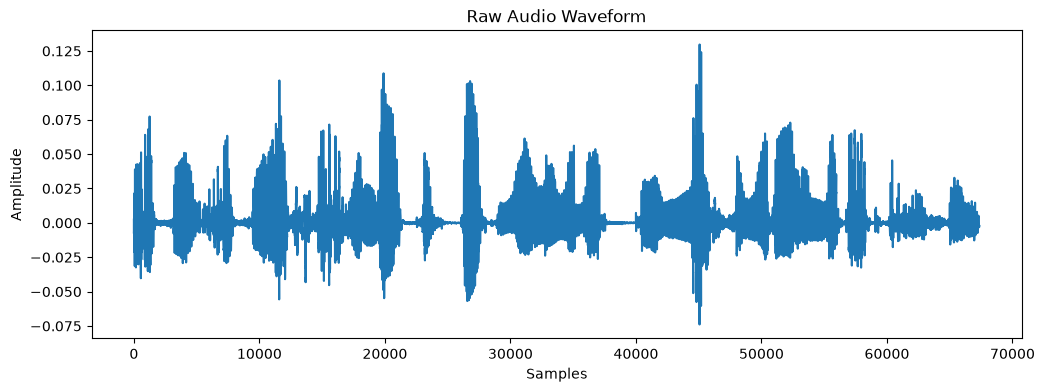

In [15]:
raw_file = os.path.join(
    TRAIN_RAW,
    "audio_000.wav"
)

processed_file = os.path.join(
    TRAIN_PROCESSED,
    "audio_000.wav"
)

raw_audio, raw_sr = librosa.load(
    raw_file,
    sr=None
)

processed_audio, processed_sr = librosa.load(
    processed_file,
    sr=None
)

plt.figure(figsize=(12, 4))

plt.plot(raw_audio)

plt.title("Raw Audio Waveform")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.show()

# 16. Visualize the Processed Audio Waveform

This cell plots the waveform of the processed audio.

The waveform shows how the audio amplitude changes over time.

Comparing this plot with the raw waveform helps visually demonstrate the effect of preprocessing, especially normalization and conversion to a consistent audio format.

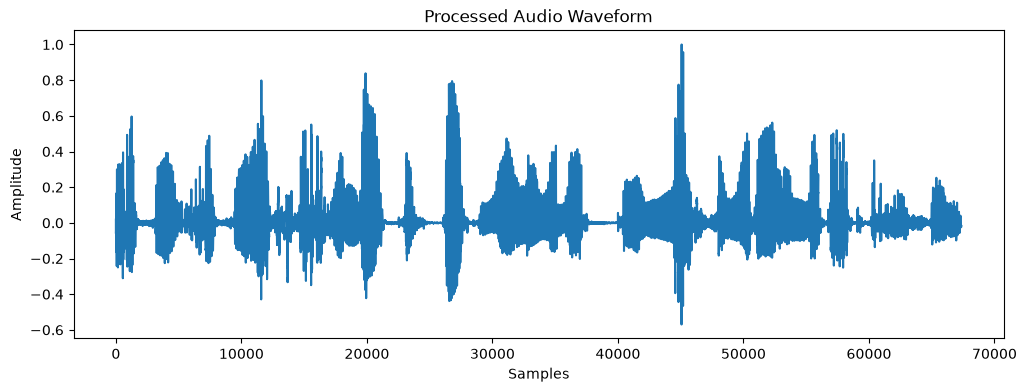

In [16]:
plt.figure(figsize=(12, 4))

plt.plot(processed_audio)

plt.title("Processed Audio Waveform")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.show()

# 17. Preprocessing Complete

The preprocessing pipeline is now complete.

The project should contain:

- **80 raw training audio files**
- **20 raw testing audio files**
- **80 processed training audio files**
- **20 processed testing audio files**

The processed audio is now ready to be used as input for the two ASR models:

1. **Whisper**
2. **AssemblyAI**

The next notebook can focus on running Whisper transcription and evaluating its results.